In [2]:
import pandas as pd

laser_power = [100, 102, 98, 101, 99]

df = pd.DataFrame({
    "Laser_Power": laser_power
})

df["Laser_Power"].mean()
df["Laser_Power"].median() #求中位数

np.float64(100.0)

In [6]:
import pandas as pd

df = pd.DataFrame({
    "Tool_A": [98, 99, 100, 101, 102],
    "Tool_B": [90, 95, 100, 105, 110]
})

#求标准偏差（N-1）
df["Tool_A"].std()
#求标准偏差（N）
df["Tool_A"].std(ddof=0)
#ddof=0：总体标准差，分母为 N。
#ddof=1：样本标准差，分母为 N-1，也是 Pandas 默认值。

df["Tool_A"].var()
df["Tool_A"].var(ddof=0)
#.var()：默认样本方差。
#.var(ddof=0)：总体方差。

np.float64(2.0)

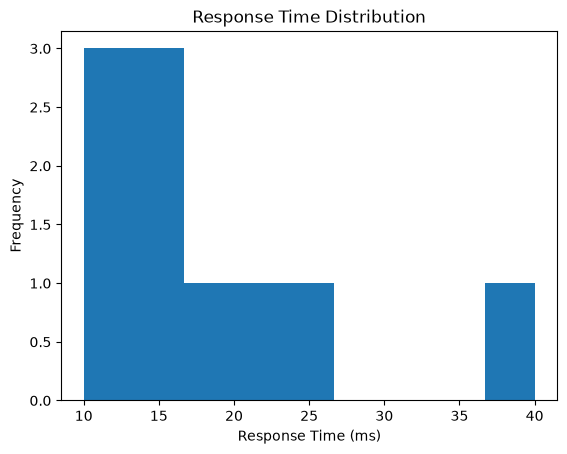

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

response_time = [10, 12, 13, 14, 15,
                 16, 18, 20, 25, 40]
df = pd.DataFrame({
    "Response_Time": response_time
})


#计算 P90（90th Percentile）
#P90 表示一个位置值，使得约 90% 的数据不超过这个值
df["Response_Time"].quantile(0.90)
#一次计算多个百分位数
df["Response_Time"].quantile([0.50, 0.90, 0.95, 0.99])

#画respond time的直方图
plt.hist(df["Response_Time"], bins=9)

plt.xlabel("Response Time (ms)")
plt.ylabel("Frequency")
plt.title("Response Time Distribution")

plt.show()

In [12]:
import pandas as pd

df = pd.DataFrame({
    "Temperature": [40, 45, 50, 55, 60],
    "Defect_Count": [10, 15, 20, 28, 35]
})

#以下两行代码所得到的相关系数是一样的,相关系数和斜率不同
df["Temperature"].corr(df["Defect_Count"])
df["Defect_Count"].corr(df["Temperature"])

np.float64(0.9946266402723094)

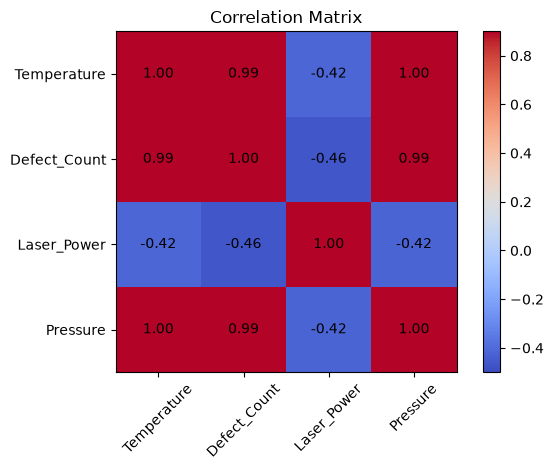

In [22]:
import pandas as pd

df = pd.DataFrame({
    "Temperature": [40, 45, 50, 55, 60],
    "Defect_Count": [10, 15, 20, 28, 35],
    "Laser_Power": [100, 102, 101, 99, 100],
    "Pressure": [20, 22, 25, 27, 30]
})

df.corr()

#使用 Matplotlib
import matplotlib.pyplot as plt

corr_matrix = df.corr()

#plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
#plt.imshow(corr_matrix, cmap="jet", vmin=-1, vmax=1)
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-0.5, vmax=0.9)


plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

#在 Heatmap 中直接显示每个格子的相关系数
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        plt.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()

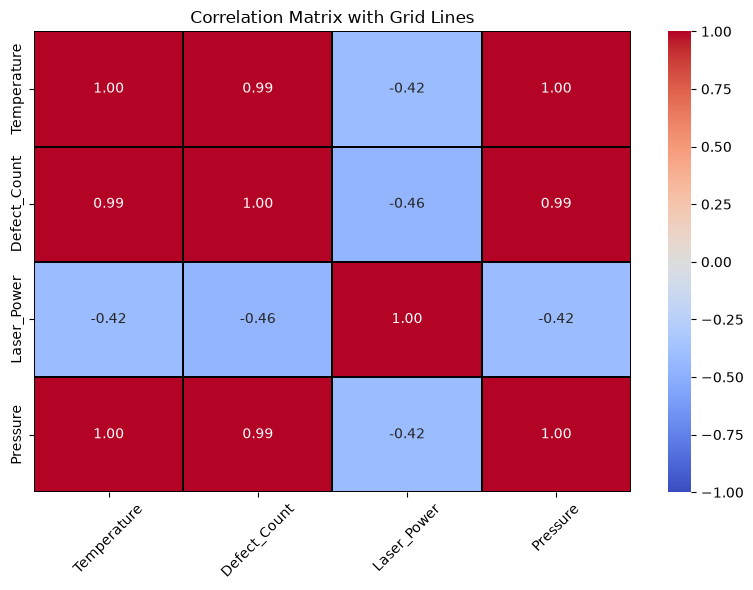

In [26]:
#加黑边的
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  # 新增：导入 seaborn

df = pd.DataFrame({
    "Temperature": [40, 45, 50, 55, 60],
    "Defect_Count": [10, 15, 20, 28, 35],
    "Laser_Power": [100, 102, 101, 99, 100],
    "Pressure": [20, 22, 25, 27, 30]
})

corr_matrix = df.corr()

# 设置画布大小
plt.figure(figsize=(8, 6))

# 核心修改：使用 sns.heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,          # 在格子里显示数字
    fmt=".2f",           # 数字保留两位小数
    cmap="coolwarm",     # 颜色方案：红-白-蓝（或者换成你喜欢的 'YlGnBu', 'viridis' 等）
    vmin=-1, vmax=1,     # 锁定颜色范围，让 0 始终是白色/中心色
    linewidths=0.2,        # 新增：格子的线宽（这就是黑边的粗度）
    linecolor='black'    # 新增：格子的边框颜色（黑色）
)

plt.title("Correlation Matrix with Grid Lines")

# 调整一下 X 轴标签，防止重叠（sns 默认会处理好 Y 轴）
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()